In [1]:
# Task 1: Download the MIT-BIH database from PhysioNet using wfdb
!pip install -q wfdb
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
warnings.filterwarnings('ignore')
np.random.seed(42)

DB_DIR = 'mitdb'
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    wfdb.dl_database('mitdb', DB_DIR)
records = sorted(f[:-4] for f in os.listdir(DB_DIR) if f.endswith('.dat'))
print('Records downloaded:', len(records))

Records downloaded: 48


Sampling frequency: 360 Hz | Leads: ['MLII', 'V5']


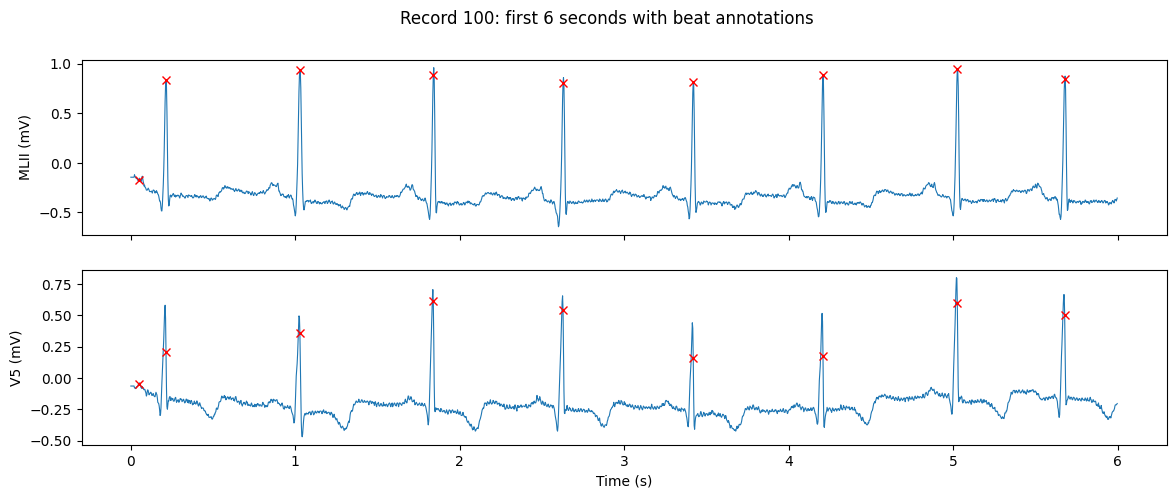

In [2]:
# Task 1: Plot signals
rec = wfdb.rdrecord(os.path.join(DB_DIR, '100'), sampto=2160)
ann = wfdb.rdann(os.path.join(DB_DIR, '100'), 'atr', sampto=2160)
print('Sampling frequency:', rec.fs, 'Hz | Leads:', rec.sig_name)
t = np.arange(rec.p_signal.shape[0]) / rec.fs
fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
for k in range(2):
    axes[k].plot(t, rec.p_signal[:, k], lw=0.8)
    axes[k].plot(ann.sample / rec.fs, rec.p_signal[ann.sample, k], 'rx')
    axes[k].set_ylabel(rec.sig_name[k] + ' (mV)')
axes[1].set_xlabel('Time (s)')
fig.suptitle('Record 100: first 6 seconds with beat annotations')
plt.show()

All annotation symbols: {'N': 75052, 'L': 8075, 'R': 7259, 'V': 7130, '/': 7028, 'A': 2546, '+': 1291, 'f': 982, 'F': 803, '~': 616, '!': 472, '"': 437, 'j': 229, 'x': 193, 'a': 150, '|': 132, 'E': 106, 'J': 83, 'Q': 33, 'e': 16, '[': 6, ']': 6, 'S': 2}
Paced records removed: ['102', '104', '107', '217'] | Records kept: 44
Beat-level class distribution after removing non-beat annotations:
N    90125
S     2781
V     7009
F      803
Q       15


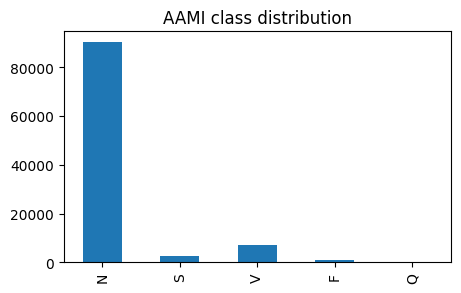

In [3]:
# Task 1: Check the class distribution (AAMI classes N, S, V, F, Q) and remove paced records and non-beat annotations
PACED = ['102', '104', '107', '217']
AAMI = {'N': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N',
        'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S',
        'V': 'V', 'E': 'V', 'F': 'F',
        '/': 'Q', 'f': 'Q', 'Q': 'Q'}
annotations = {r: wfdb.rdann(os.path.join(DB_DIR, r), 'atr') for r in records}
all_symbols = pd.Series([s for a in annotations.values() for s in a.symbol]).value_counts()
print('All annotation symbols:', all_symbols.to_dict())

records = [r for r in records if r not in PACED]
print('Paced records removed:', PACED, '| Records kept:', len(records))

beats = {}
for r in records:
    a = annotations[r]
    keep = [i for i, s in enumerate(a.symbol) if s in AAMI]
    beats[r] = (a.sample[keep], np.array([AAMI[a.symbol[i]] for i in keep]))
dist = pd.Series(np.concatenate([b[1] for b in beats.values()])).value_counts().reindex(['N', 'S', 'V', 'F', 'Q'])
print('Beat-level class distribution after removing non-beat annotations:')
print(dist.to_string())
dist.plot(kind='bar', figsize=(5, 3), title='AAMI class distribution')
plt.show()

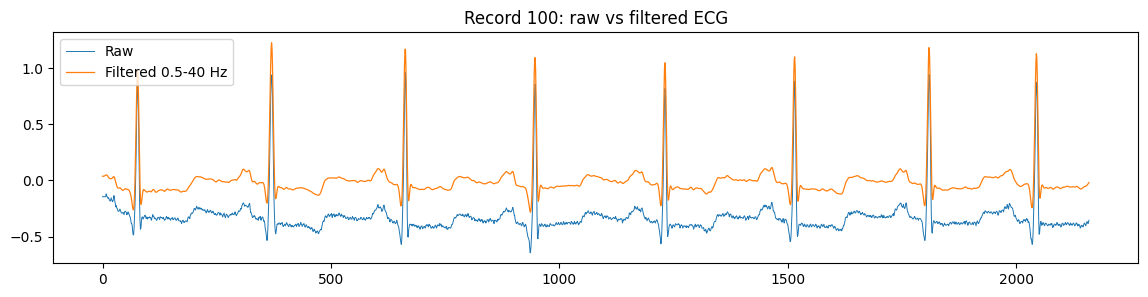

In [4]:
# Task 2: Remove baseline wander and noise with a 0.5-40 Hz bandpass filter
from scipy.signal import butter, filtfilt
FS = 360
b_coef, a_coef = butter(3, [0.5, 40], btype='bandpass', fs=FS)
raw_signals, signals = {}, {}
for r in records:
    rec = wfdb.rdrecord(os.path.join(DB_DIR, r))
    ch = rec.sig_name.index('MLII') if 'MLII' in rec.sig_name else 0
    raw_signals[r] = rec.p_signal[:, ch]
    signals[r] = filtfilt(b_coef, a_coef, raw_signals[r])
seg = slice(0, 2160)
plt.figure(figsize=(14, 3))
plt.plot(raw_signals['100'][seg], lw=0.7, label='Raw')
plt.plot(signals['100'][seg], lw=0.9, label='Filtered 0.5-40 Hz')
plt.legend()
plt.title('Record 100: raw vs filtered ECG')
plt.show()

In [5]:
# Task 2: Extract fixed-length windows around each R-peak with its beat label
WIN = 180
segments = {}
for r in records:
    sig = signals[r]
    samples, labs = beats[r]
    Xr, yr = [], []
    for s, l in zip(samples, labs):
        if s - WIN // 2 >= 0 and s + WIN // 2 <= len(sig):
            Xr.append(sig[s - WIN // 2:s + WIN // 2])
            yr.append(l)
    segments[r] = (np.array(Xr, dtype=np.float32), np.array(yr))
print('Total beat windows:', sum(len(v[1]) for v in segments.values()), '| Window length:', WIN, 'samples')

Total beat windows: 100708 | Window length: 180 samples


In [6]:
# Task 2: Extract features using raw beat morphology
CLASSES = ['N', 'S', 'V', 'F', 'Q']
class_index = {c: i for i, c in enumerate(CLASSES)}
features = {r: (v[0][:, :, None], np.array([class_index[l] for l in v[1]])) for r, v in segments.items()}
print('Feature array for record 100 (beats, time steps, channels):', features['100'][0].shape)

Feature array for record 100 (beats, time steps, channels): (2271, 180, 1)


In [7]:
# Task 2: Normalize each beat window to a consistent scale
for r in features:
    Xr, yr = features[r]
    mean = Xr.mean(axis=1, keepdims=True)
    std = Xr.std(axis=1, keepdims=True)
    features[r] = ((Xr - mean) / (std + 1e-8), yr)
print('Beat mean (first beat of record 100):', round(float(features['100'][0][0].mean()), 4), '| std:', round(float(features['100'][0][0].std()), 4))

Beat mean (first beat of record 100): -0.0 | std: 1.0


In [8]:
# Task 2: Create inter-patient training, validation and test sets
DS1 = ['101', '106', '108', '109', '112', '114', '115', '116', '118', '119', '122', '124', '201', '203', '205', '207', '208', '209', '215', '220', '223', '230']
DS2 = ['100', '103', '105', '111', '113', '117', '121', '123', '200', '202', '210', '212', '213', '214', '219', '221', '222', '228', '231', '232', '233', '234']
VAL = ['106', '118', '124', '208', '215']
TRAIN = [r for r in DS1 if r not in VAL]
TEST = DS2

def stack(recs):
    return np.concatenate([features[r][0] for r in recs]), np.concatenate([features[r][1] for r in recs])

X_train, y_train = stack(TRAIN)
X_val, y_val = stack(VAL)
X_test, y_test = stack(TEST)
for name, yy in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    print(name, len(yy), dict(zip(CLASSES, np.bincount(yy, minlength=5).tolist())))

Train 38771 {'N': 35868, 'S': 812, 'V': 2049, 'F': 36, 'Q': 6}
Validation 12239 {'N': 9988, 'S': 132, 'V': 1739, 'F': 378, 'Q': 2}
Test 49698 {'N': 44246, 'S': 1837, 'V': 3220, 'F': 388, 'Q': 7}


In [9]:
# Task 2: Handle class imbalance with class weights
class_counts = np.bincount(y_train, minlength=5).astype(float)
class_weights = np.sqrt(len(y_train) / (5 * np.maximum(class_counts, 1)))
class_weights = np.clip(class_weights, 0, 8)
print('Class weights:', dict(zip(CLASSES, class_weights.round(3).tolist())))

Class weights: {'N': 0.465, 'S': 3.09, 'V': 1.945, 'F': 8.0, 'Q': 8.0}


In [10]:
# Task 3: Build comparable RNN, LSTM and GRU classifiers
import copy
import torch
import torch.nn as nn
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class BeatClassifier(nn.Module):
    def __init__(self, kind):
        super().__init__()
        layer = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[kind]
        self.rnn = layer(1, 64, num_layers=1, batch_first=True)
        self.fc = nn.Linear(64, 5)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

for kind in ['RNN', 'LSTM', 'GRU']:
    print(kind, 'parameters:', sum(p.numel() for p in BeatClassifier(kind).parameters()))
print('Device:', device)

RNN parameters: 4613
LSTM parameters: 17477
GRU parameters: 13189
Device: cuda


In [11]:
# Task 3: Define identical training settings with early stopping
Xtr = torch.tensor(X_train, dtype=torch.float32, device=device)
ytr = torch.tensor(y_train, dtype=torch.long, device=device)
Xva = torch.tensor(X_val, dtype=torch.float32, device=device)
yva = torch.tensor(y_val, dtype=torch.long, device=device)
Xte = torch.tensor(X_test, dtype=torch.float32, device=device)
weight_tensor = torch.tensor(class_weights, dtype=torch.float32, device=device)
BATCH, MAX_EPOCHS, PATIENCE, LR = 256, 40, 8, 2e-3

def predict(model, X):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), 2048):
            out.append(model(X[i:i + 2048]).argmax(1))
    return torch.cat(out).cpu().numpy()

def train_model(kind):
    torch.manual_seed(42)
    model = BeatClassifier(kind).to(device)
    criterion = nn.CrossEntropyLoss(weight=weight_tensor)
    val_criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    best, best_state, wait = float('inf'), None, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        perm = torch.randperm(len(Xtr), device=device)
        total = 0.0
        for i in range(0, len(Xtr), BATCH):
            idx = perm[i:i + BATCH]
            loss = criterion(model(Xtr[idx]), ytr[idx])
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val_loss = sum(val_criterion(model(Xva[i:i + 2048]), yva[i:i + 2048]).item() * len(Xva[i:i + 2048]) for i in range(0, len(Xva), 2048)) / len(Xva)
        val_acc = float((predict(model, Xva) == y_val).mean())
        print(kind, 'epoch', epoch, '| train loss', round(total / len(Xtr), 4), '| val loss', round(val_loss, 4), '| val acc', round(val_acc, 4))
        if val_loss < best:
            best, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE:
                print(kind, 'early stopping at epoch', epoch)
                break
    model.load_state_dict(best_state)
    return model

trained = {}

In [12]:
# Task 3: Train and validate the RNN
trained['RNN'] = train_model('RNN')

RNN epoch 1 | train loss 0.8722 | val loss 0.6834 | val acc 0.8194
RNN epoch 2 | train loss 0.7706 | val loss 0.6576 | val acc 0.8225
RNN epoch 3 | train loss 0.6837 | val loss 0.6289 | val acc 0.87
RNN epoch 4 | train loss 0.6752 | val loss 0.5275 | val acc 0.8973
RNN epoch 5 | train loss 0.6714 | val loss 0.5488 | val acc 0.8908
RNN epoch 6 | train loss 0.65 | val loss 0.5665 | val acc 0.9005
RNN epoch 7 | train loss 0.6382 | val loss 0.6151 | val acc 0.879
RNN epoch 8 | train loss 0.6463 | val loss 0.595 | val acc 0.8768
RNN epoch 9 | train loss 0.6309 | val loss 0.5522 | val acc 0.8964
RNN epoch 10 | train loss 0.6365 | val loss 0.7844 | val acc 0.8323
RNN epoch 11 | train loss 0.62 | val loss 0.6278 | val acc 0.8364
RNN epoch 12 | train loss 0.6547 | val loss 0.5212 | val acc 0.8929
RNN epoch 13 | train loss 0.6401 | val loss 0.764 | val acc 0.8312
RNN epoch 14 | train loss 0.6419 | val loss 0.4969 | val acc 0.8935
RNN epoch 15 | train loss 0.6558 | val loss 0.7291 | val acc 0.842

In [13]:
# Task 3: Train and validate the LSTM
trained['LSTM'] = train_model('LSTM')

LSTM epoch 1 | train loss 0.8958 | val loss 0.65 | val acc 0.8203
LSTM epoch 2 | train loss 0.6869 | val loss 0.4642 | val acc 0.9212
LSTM epoch 3 | train loss 0.584 | val loss 0.9506 | val acc 0.731
LSTM epoch 4 | train loss 0.5404 | val loss 0.4779 | val acc 0.9271
LSTM epoch 5 | train loss 0.4847 | val loss 0.5158 | val acc 0.9283
LSTM epoch 6 | train loss 0.4455 | val loss 0.5792 | val acc 0.7785
LSTM epoch 7 | train loss 0.4152 | val loss 0.5782 | val acc 0.8362
LSTM epoch 8 | train loss 0.3832 | val loss 0.9713 | val acc 0.6594
LSTM epoch 9 | train loss 0.3487 | val loss 0.8406 | val acc 0.7157
LSTM epoch 10 | train loss 0.2961 | val loss 0.7174 | val acc 0.7401
LSTM early stopping at epoch 10


In [14]:
# Task 3: Train and validate the GRU
trained['GRU'] = train_model('GRU')

GRU epoch 1 | train loss 0.8792 | val loss 0.6362 | val acc 0.8211
GRU epoch 2 | train loss 0.5653 | val loss 0.7974 | val acc 0.6987
GRU epoch 3 | train loss 0.4493 | val loss 0.5141 | val acc 0.8715
GRU epoch 4 | train loss 0.3911 | val loss 0.9371 | val acc 0.6501
GRU epoch 5 | train loss 0.3798 | val loss 0.8696 | val acc 0.724
GRU epoch 6 | train loss 0.334 | val loss 0.7266 | val acc 0.7537
GRU epoch 7 | train loss 0.305 | val loss 0.8068 | val acc 0.7446
GRU epoch 8 | train loss 0.3005 | val loss 0.6329 | val acc 0.818
GRU epoch 9 | train loss 0.2716 | val loss 0.5607 | val acc 0.8597
GRU epoch 10 | train loss 0.2598 | val loss 0.6658 | val acc 0.8425
GRU epoch 11 | train loss 0.2417 | val loss 0.575 | val acc 0.8781
GRU early stopping at epoch 11


In [15]:
# Task 3: Compare accuracy, precision, recall and F1 on the test set
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
test_preds, rows = {}, []
for kind, model in trained.items():
    p = predict(model, Xte)
    test_preds[kind] = p
    pr, rc, f1, _ = precision_recall_fscore_support(y_test, p, average='macro', zero_division=0)
    rows.append({'Model': kind, 'Accuracy': accuracy_score(y_test, p), 'Precision (macro)': pr, 'Recall (macro)': rc, 'F1 (macro)': f1})
results = pd.DataFrame(rows).set_index('Model').round(4)
print(results.to_string())
for kind, p in test_preds.items():
    print()
    print(kind)
    print(classification_report(y_test, p, labels=list(range(5)), target_names=CLASSES, zero_division=0, digits=3))

       Accuracy  Precision (macro)  Recall (macro)  F1 (macro)
Model                                                         
RNN      0.8079             0.2067          0.2274      0.2139
LSTM     0.8046             0.2127          0.2415      0.2215
GRU      0.8510             0.2678          0.3186      0.2857

RNN
              precision    recall  f1-score   support

           N      0.897     0.889     0.893     44246
           S      0.000     0.000     0.000      1837
           V      0.137     0.248     0.176      3220
           F      0.000     0.000     0.000       388
           Q      0.000     0.000     0.000         7

    accuracy                          0.808     49698
   macro avg      0.207     0.227     0.214     49698
weighted avg      0.808     0.808     0.807     49698


LSTM
              precision    recall  f1-score   support

           N      0.901     0.880     0.890     44246
           S      0.000     0.000     0.000      1837
           V      0.16

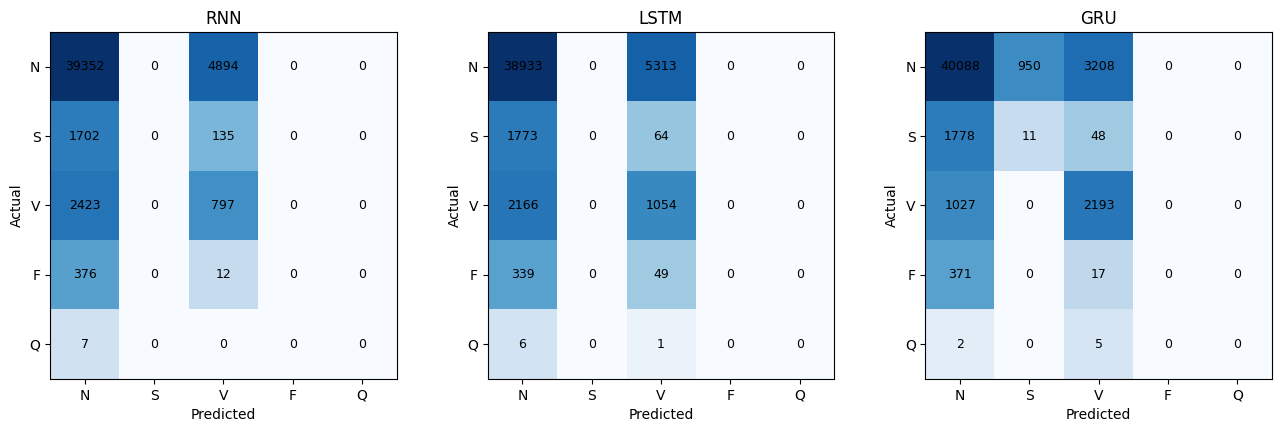

In [16]:
# Task 3: Compare confusion matrices on the test set
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (kind, p) in zip(axes, test_preds.items()):
    cm = confusion_matrix(y_test, p, labels=list(range(5)))
    ax.imshow(np.log1p(cm), cmap='Blues')
    ax.set_xticks(range(5))
    ax.set_xticklabels(CLASSES)
    ax.set_yticks(range(5))
    ax.set_yticklabels(CLASSES)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(kind)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=9)
plt.show()